# HiFi-GAN をゼロから作る（mel-to-waveform ボコーダ）

メルスペクトログラムから波形を生成する HiFi-GAN（Kong et al., NeurIPS 2020）を、Google Colab 上で一から実装・学習するノートブックです。

## 使い方
1. **ランタイム → ランタイムのタイプを変更 → GPU**（L4 / A100 推奨）を選ぶ
2. 上から順にすべてのセルを実行する
3. 切断されたら、もう一度上から実行するだけで **Google Drive のチェックポイントから学習を再開** します

## 保存先（Google Drive）
`MyDrive/hifigan-book/` 以下に次のものが保存されます。
- `checkpoints/` … 学習再開用の `ckpt_latest.pt`、節目ごとの生成器 `g_XXXXXXX.pt`
- `samples/` … 節目ごとの生成音声と、メルスペクトログラムの比較図（本の図にそのまま使えます）
- `logs/` … TensorBoard のログ

## データセット
LJSpeech 1.1（英語・女性話者1名・約24時間・22.05kHz）を使います。**パブリックドメイン**なので、頒布する本でも扱いやすく、HiFi-GAN 論文と同じ条件で比較できます。

## 0. 環境の確認と Google Drive のマウント

In [ ]:
!nvidia-smi

Tue Nov  3 03:02:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             51W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/hifigan-book'
CKPT_DIR = f'{PROJECT_DIR}/checkpoints'
SAMPLE_DIR = f'{PROJECT_DIR}/samples'
LOG_DIR = f'{PROJECT_DIR}/logs'
DATA_DIR = '/content/data'  # 音声データは高速なローカルディスクに置く

for d in [CKPT_DIR, SAMPLE_DIR, LOG_DIR, DATA_DIR]:
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


## 1. 設定

`CONFIG_NAME` でモデルの大きさを選びます（論文の V1 / V2 / V3）。

| 設定 | パラメータ数 | 特徴 |
|---|---|---|
| v1 | 約13.9M | 高品質（本命） |
| v2 | 約0.9M | 軽量・高速（まず動作確認するならこれ） |
| v3 | 約1.5M | 軽量・最速。残差ブロックの構造が違う |

In [ ]:
import math
from types import SimpleNamespace

CONFIG_NAME = 'v1'  # 'v1' | 'v2' | 'v3'

MODEL_CONFIGS = {
    'v1': dict(resblock='1', upsample_initial_channel=512,
               upsample_rates=[8, 8, 2, 2], upsample_kernel_sizes=[16, 16, 4, 4],
               resblock_kernel_sizes=[3, 7, 11], resblock_dilation_sizes=[[1, 3, 5]] * 3),
    'v2': dict(resblock='1', upsample_initial_channel=128,
               upsample_rates=[8, 8, 2, 2], upsample_kernel_sizes=[16, 16, 4, 4],
               resblock_kernel_sizes=[3, 7, 11], resblock_dilation_sizes=[[1, 3, 5]] * 3),
    'v3': dict(resblock='2', upsample_initial_channel=256,
               upsample_rates=[8, 8, 4], upsample_kernel_sizes=[16, 16, 8],
               resblock_kernel_sizes=[3, 5, 7], resblock_dilation_sizes=[[1, 2], [2, 6], [3, 12]]),
}

h = SimpleNamespace(
    **MODEL_CONFIGS[CONFIG_NAME],
    # 音声・メルの設定（論文 / 公式実装と同じ）
    sampling_rate=22050, segment_size=8192,
    n_fft=1024, hop_size=256, win_size=1024,
    num_mels=80, fmin=0, fmax=8000, fmax_for_loss=None,
    # 学習の設定
    batch_size=16, learning_rate=2e-4, adam_b1=0.8, adam_b2=0.99, lr_decay=0.999,
    lambda_fm=2.0, lambda_mel=45.0,
)

# 学習ループの設定
MAX_STEPS = 500_000      # 上限（実際は時間の許す限り回して、途中で止めてよい）
LOG_INTERVAL = 100       # TensorBoard に損失を書く間隔
VAL_INTERVAL = 1000      # 検証データでメル誤差を測る間隔
CKPT_INTERVAL = 2000     # ckpt_latest.pt を上書き保存する間隔
# 音声サンプルと生成器を残す節目（本の「学習の進み方」の図に使う）
MILESTONES = {0, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 300000, 400000, 500000}
SAMPLE_INTERVAL = 25000  # 節目以外にも、この間隔でサンプルを残す
NUM_SAMPLE_UTTS = 4      # 毎回サンプルを作る検証用発話の数
NUM_VAL_UTTS = 32        # メル誤差を測る検証用発話の数
assert h.hop_size == math.prod(h.upsample_rates), 'アップサンプル倍率の積は hop_size と一致させる'

## 2. データの準備（LJSpeech）

アーカイブ（約2.6GB）は一度だけダウンロードして Google Drive に置き、再接続のときはそこから展開します。

In [ ]:
import subprocess, glob, json, random

LJ_URL = 'https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2'
WAV_DIR = f'{DATA_DIR}/LJSpeech-1.1/wavs'
archive = f'{PROJECT_DIR}/LJSpeech-1.1.tar.bz2'

if not os.path.isdir(WAV_DIR):
    if not os.path.exists(archive):
        print('LJSpeech をダウンロード中...')
        subprocess.run(['wget', '-q', '--show-progress', '-O', archive + '.tmp', LJ_URL], check=True)
        os.replace(archive + '.tmp', archive)
    print('展開中...（数分かかります）')
    subprocess.run(['tar', '-xjf', archive, '-C', DATA_DIR], check=True)

# 学習 / 検証の分割は Drive に保存して、再開しても同じ分割を使う
split_path = f'{PROJECT_DIR}/split.json'
if os.path.exists(split_path):
    with open(split_path) as f:
        split = json.load(f)
else:
    names = sorted(os.path.basename(p) for p in glob.glob(f'{WAV_DIR}/*.wav'))
    random.Random(1234).shuffle(names)
    split = {'val': names[:100], 'train': names[100:]}
    with open(split_path, 'w') as f:
        json.dump(split, f)

train_files = [f'{WAV_DIR}/{n}' for n in split['train']]
val_files = [f'{WAV_DIR}/{n}' for n in split['val']]
print(f'train: {len(train_files)} 発話, val: {len(val_files)} 発話')

展開中...（数分かかります）
train: 13000 発話, val: 100 発話


## 3. メルスペクトログラム

公式実装と同じく、`center=False` で両端を `(n_fft - hop) / 2` だけ反射パディングします。こうすると **メルの1フレームが、ちょうど波形の `hop_size` サンプルに対応** します（8192サンプル → 32フレーム）。

- `fmax=8000` … 生成器への**入力**用
- `fmax=None`（ナイキスト周波数まで） … **メル損失**用。高い周波数まで正しく作れているかを見る

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from librosa.filters import mel as librosa_mel_fn

_mel_basis = {}
_hann_window = {}


def mel_spectrogram(y, n_fft, num_mels, sampling_rate, hop_size, win_size, fmin, fmax):
    # y: (B, T) の波形（-1〜1）→ (B, num_mels, T // hop_size) の対数メル
    key = (fmax, str(y.device))
    if key not in _mel_basis:
        mel = librosa_mel_fn(sr=sampling_rate, n_fft=n_fft, n_mels=num_mels, fmin=fmin, fmax=fmax)
        _mel_basis[key] = torch.from_numpy(mel).float().to(y.device)
    if str(y.device) not in _hann_window:
        _hann_window[str(y.device)] = torch.hann_window(win_size).to(y.device)

    pad = (n_fft - hop_size) // 2
    y = F.pad(y.unsqueeze(1), (pad, pad), mode='reflect').squeeze(1)
    spec = torch.stft(y, n_fft, hop_length=hop_size, win_length=win_size,
                      window=_hann_window[str(y.device)], center=False,
                      normalized=False, onesided=True, return_complex=True)
    spec = torch.sqrt(spec.real ** 2 + spec.imag ** 2 + 1e-9)  # 振幅（位相はここで捨てられる）
    spec = torch.matmul(_mel_basis[key], spec)                 # メル周波数に圧縮
    return torch.log(torch.clamp(spec, min=1e-5))              # 対数をとる


def mel_input(y):
    return mel_spectrogram(y, h.n_fft, h.num_mels, h.sampling_rate, h.hop_size, h.win_size, h.fmin, h.fmax)


def mel_for_loss(y):
    return mel_spectrogram(y, h.n_fft, h.num_mels, h.sampling_rate, h.hop_size, h.win_size, h.fmin, h.fmax_for_loss)

## 4. データセット

学習時は各発話からランダムに 8192 サンプル（約0.37秒）を切り出し、そのメルを入力、波形を正解にします。

In [ ]:
import soundfile as sf
from torch.utils.data import Dataset, DataLoader


def load_wav(path):
    audio, sr = sf.read(path, dtype='float32')
    assert sr == h.sampling_rate, f'{path}: {sr}Hz（{h.sampling_rate}Hz を想定）'
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    audio = audio / (np.abs(audio).max() + 1e-8) * 0.95  # 公式実装と同じ音量正規化
    return torch.from_numpy(audio)


class MelDataset(Dataset):
    def __init__(self, files, segment_size=None):
        self.files = files
        self.segment_size = segment_size  # None なら発話全体を返す（検証用）

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        audio = load_wav(self.files[i])
        if self.segment_size is not None:
            if len(audio) >= self.segment_size:
                start = torch.randint(0, len(audio) - self.segment_size + 1, ()).item()
                audio = audio[start:start + self.segment_size]
            else:
                audio = F.pad(audio, (0, self.segment_size - len(audio)))
        else:
            audio = audio[:len(audio) // h.hop_size * h.hop_size]  # hop の倍数にそろえる
        mel = mel_input(audio.unsqueeze(0)).squeeze(0)
        return mel, audio

## 5. モデル

### Generator
メル（80 × T）を、転置畳み込みで段階的に 256 倍まで引き伸ばします。各段の後ろには **MRF（Multi-Receptive Field Fusion）** があり、カーネルサイズと膨張率の違う残差ブロックの出力を平均します。

### Discriminator
- **MPD（Multi-Period Discriminator）** … 波形を周期 p（2, 3, 5, 7, 11）ごとに2次元に並べ直して判定。周期構造を見る
- **MSD（Multi-Scale Discriminator）** … 原音・1/2・1/4 にダウンサンプルした波形を判定。いろいろな時間スケールを見る

※ 重みの初期化は、公式実装で**実際に効いている状態**（PyTorch 既定の初期化 + weight norm）に合わせています。

In [ ]:
import torch.nn as nn
from torch.nn.utils.parametrizations import weight_norm, spectral_norm

LRELU_SLOPE = 0.1


def get_padding(kernel_size, dilation=1):
    return (kernel_size * dilation - dilation) // 2


class ResBlock1(nn.Module):
    # V1 / V2 用: 膨張畳み込み → 通常の畳み込み、を3回繰り返す残差ブロック
    def __init__(self, ch, kernel_size=3, dilation=(1, 3, 5)):
        super().__init__()
        self.convs1 = nn.ModuleList([
            weight_norm(nn.Conv1d(ch, ch, kernel_size, 1, dilation=d, padding=get_padding(kernel_size, d)))
            for d in dilation])
        self.convs2 = nn.ModuleList([
            weight_norm(nn.Conv1d(ch, ch, kernel_size, 1, dilation=1, padding=get_padding(kernel_size, 1)))
            for _ in dilation])

    def forward(self, x):
        for c1, c2 in zip(self.convs1, self.convs2):
            xt = c1(F.leaky_relu(x, LRELU_SLOPE))
            xt = c2(F.leaky_relu(xt, LRELU_SLOPE))
            x = x + xt
        return x


class ResBlock2(nn.Module):
    # V3 用: 膨張畳み込みだけの軽い残差ブロック
    def __init__(self, ch, kernel_size=3, dilation=(1, 3)):
        super().__init__()
        self.convs = nn.ModuleList([
            weight_norm(nn.Conv1d(ch, ch, kernel_size, 1, dilation=d, padding=get_padding(kernel_size, d)))
            for d in dilation])

    def forward(self, x):
        for c in self.convs:
            x = x + c(F.leaky_relu(x, LRELU_SLOPE))
        return x


class Generator(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.num_kernels = len(h.resblock_kernel_sizes)
        ch = h.upsample_initial_channel
        self.conv_pre = weight_norm(nn.Conv1d(h.num_mels, ch, 7, 1, padding=3))

        resblock = ResBlock1 if h.resblock == '1' else ResBlock2
        self.ups = nn.ModuleList()
        self.resblocks = nn.ModuleList()
        for i, (u, k) in enumerate(zip(h.upsample_rates, h.upsample_kernel_sizes)):
            # 転置畳み込みで時間方向を u 倍、チャネルは半分に
            self.ups.append(weight_norm(nn.ConvTranspose1d(ch // 2 ** i, ch // 2 ** (i + 1), k, u, padding=(k - u) // 2)))
            for rk, rd in zip(h.resblock_kernel_sizes, h.resblock_dilation_sizes):
                self.resblocks.append(resblock(ch // 2 ** (i + 1), rk, rd))

        self.conv_post = weight_norm(nn.Conv1d(ch // 2 ** len(h.upsample_rates), 1, 7, 1, padding=3))

    def forward(self, x):
        # x: (B, num_mels, T) → (B, 1, T * hop_size)
        x = self.conv_pre(x)
        for i, up in enumerate(self.ups):
            x = up(F.leaky_relu(x, LRELU_SLOPE))
            # MRF: 受容野の違う残差ブロックの出力を平均する
            xs = sum(self.resblocks[i * self.num_kernels + j](x) for j in range(self.num_kernels))
            x = xs / self.num_kernels
        x = self.conv_post(F.leaky_relu(x))  # 公式実装どおり、最後だけ傾き 0.01
        return torch.tanh(x)


class DiscriminatorP(nn.Module):
    def __init__(self, period, kernel_size=5, stride=3):
        super().__init__()
        self.period = period
        chs = [1, 32, 128, 512, 1024]
        self.convs = nn.ModuleList([
            weight_norm(nn.Conv2d(chs[i], chs[i + 1], (kernel_size, 1), (stride, 1), padding=(get_padding(kernel_size), 0)))
            for i in range(4)])
        self.convs.append(weight_norm(nn.Conv2d(1024, 1024, (kernel_size, 1), 1, padding=(2, 0))))
        self.conv_post = weight_norm(nn.Conv2d(1024, 1, (3, 1), 1, padding=(1, 0)))

    def forward(self, x):
        fmap = []
        b, c, t = x.shape
        if t % self.period != 0:  # 周期で割り切れるように右端をパディング
            n_pad = self.period - t % self.period
            x = F.pad(x, (0, n_pad), mode='reflect')
            t = t + n_pad
        x = x.view(b, c, t // self.period, self.period)  # 1次元波形 → (時間/p, p) の2次元
        for layer in self.convs:
            x = F.leaky_relu(layer(x), LRELU_SLOPE)
            fmap.append(x)
        x = self.conv_post(x)
        fmap.append(x)
        return torch.flatten(x, 1, -1), fmap


class MultiPeriodDiscriminator(nn.Module):
    def __init__(self, periods=(2, 3, 5, 7, 11)):
        super().__init__()
        self.discriminators = nn.ModuleList([DiscriminatorP(p) for p in periods])

    def forward(self, y, y_hat):
        y_d_rs, y_d_gs, fmap_rs, fmap_gs = [], [], [], []
        for d in self.discriminators:
            y_d_r, fmap_r = d(y)
            y_d_g, fmap_g = d(y_hat)
            y_d_rs.append(y_d_r); fmap_rs.append(fmap_r)
            y_d_gs.append(y_d_g); fmap_gs.append(fmap_g)
        return y_d_rs, y_d_gs, fmap_rs, fmap_gs


class DiscriminatorS(nn.Module):
    def __init__(self, use_spectral_norm=False):
        super().__init__()
        norm_f = spectral_norm if use_spectral_norm else weight_norm
        self.convs = nn.ModuleList([
            norm_f(nn.Conv1d(1, 128, 15, 1, padding=7)),
            norm_f(nn.Conv1d(128, 128, 41, 2, groups=4, padding=20)),
            norm_f(nn.Conv1d(128, 256, 41, 2, groups=16, padding=20)),
            norm_f(nn.Conv1d(256, 512, 41, 4, groups=16, padding=20)),
            norm_f(nn.Conv1d(512, 1024, 41, 4, groups=16, padding=20)),
            norm_f(nn.Conv1d(1024, 1024, 41, 1, groups=16, padding=20)),
            norm_f(nn.Conv1d(1024, 1024, 5, 1, padding=2)),
        ])
        self.conv_post = norm_f(nn.Conv1d(1024, 1, 3, 1, padding=1))

    def forward(self, x):
        fmap = []
        for layer in self.convs:
            x = F.leaky_relu(layer(x), LRELU_SLOPE)
            fmap.append(x)
        x = self.conv_post(x)
        fmap.append(x)
        return torch.flatten(x, 1, -1), fmap


class MultiScaleDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        # 原音のスケールだけ spectral norm（論文どおり）
        self.discriminators = nn.ModuleList([
            DiscriminatorS(use_spectral_norm=True), DiscriminatorS(), DiscriminatorS()])
        self.meanpools = nn.ModuleList([nn.AvgPool1d(4, 2, padding=2), nn.AvgPool1d(4, 2, padding=2)])

    def forward(self, y, y_hat):
        y_d_rs, y_d_gs, fmap_rs, fmap_gs = [], [], [], []
        for i, d in enumerate(self.discriminators):
            if i != 0:  # 1/2, 1/4 にダウンサンプル
                y = self.meanpools[i - 1](y)
                y_hat = self.meanpools[i - 1](y_hat)
            y_d_r, fmap_r = d(y)
            y_d_g, fmap_g = d(y_hat)
            y_d_rs.append(y_d_r); fmap_rs.append(fmap_r)
            y_d_gs.append(y_d_g); fmap_gs.append(fmap_g)
        return y_d_rs, y_d_gs, fmap_rs, fmap_gs


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

## 6. 損失関数

| 損失 | 内容 | 重み |
|---|---|---|
| 敵対的損失（LSGAN） | 識別器の出力を、本物なら1・偽物なら0に近づける（二乗誤差） | 1 |
| 特徴マッチング損失 | 識別器の各層の特徴量が、本物と生成音で近いか（L1） | 2 |
| メル損失 | 生成波形から取り直したメルが、正解のメルと近いか（L1） | 45 |

In [ ]:
def discriminator_loss(disc_real_outputs, disc_generated_outputs):
    loss = 0
    for dr, dg in zip(disc_real_outputs, disc_generated_outputs):
        loss = loss + torch.mean((1 - dr) ** 2) + torch.mean(dg ** 2)
    return loss


def generator_loss(disc_outputs):
    loss = 0
    for dg in disc_outputs:
        loss = loss + torch.mean((1 - dg) ** 2)
    return loss


def feature_loss(fmap_r, fmap_g):
    loss = 0
    for dr, dg in zip(fmap_r, fmap_g):
        for rl, gl in zip(dr, dg):
            loss = loss + torch.mean(torch.abs(rl - gl))
    return loss

## 7. 学習

- 識別器（MPD + MSD）を1回更新 → 生成器を1回更新、を繰り返します
- `CKPT_INTERVAL` ごとに `ckpt_latest.pt` を保存します（一時ファイルに書いてから置き換えるので、保存中に切断されても壊れません）
- 節目（`MILESTONES`）では、検証用の発話を合成して `samples/step_XXXXXXX/` に音声と図を保存します

In [ ]:
import os, time, itertools
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True


def plot_mels(mels, titles, path):
    fig, axes = plt.subplots(len(mels), 1, figsize=(10, 2.6 * len(mels)), squeeze=False,
                             sharex=True, constrained_layout=True)
    for ax, m, t in zip(axes[:, 0], mels, titles):
        im = ax.imshow(m, aspect='auto', origin='lower', interpolation='none', vmin=-11.5, vmax=2.5)
        ax.set_title(t)
        ax.set_ylabel('mel bin')
    axes[-1, 0].set_xlabel('frame')
    fig.colorbar(im, ax=axes[:, 0].tolist(), shrink=0.8, label='log amplitude')
    fig.savefig(path, dpi=200)
    plt.close(fig)


@torch.no_grad()
def save_samples(generator, step):
    out_dir = f'{SAMPLE_DIR}/step_{step:07d}'
    os.makedirs(out_dir, exist_ok=True)
    generator.eval()
    for path in val_files[:NUM_SAMPLE_UTTS]:
        name = os.path.splitext(os.path.basename(path))[0]
        y = load_wav(path)
        y = y[:len(y) // h.hop_size * h.hop_size]
        mel = mel_input(y.unsqueeze(0).to(device))
        y_hat = generator(mel).squeeze().cpu()
        sf.write(f'{out_dir}/{name}_gen.wav', y_hat.numpy(), h.sampling_rate)
        ref = f'{SAMPLE_DIR}/reference/{name}_gt.wav'
        if not os.path.exists(ref):
            os.makedirs(os.path.dirname(ref), exist_ok=True)
            sf.write(ref, y.numpy(), h.sampling_rate)
        mel_hat = mel_input(y_hat.unsqueeze(0).to(device))
        plot_mels([mel[0].cpu().numpy(), mel_hat[0].cpu().numpy()],
                  ['Ground truth', f'HiFi-GAN ({CONFIG_NAME}, step {step:,})'],
                  f'{out_dir}/{name}_mel.png')
    generator.train()


@torch.no_grad()
def validate(generator):
    generator.eval()
    errors = []
    for path in val_files[:NUM_VAL_UTTS]:
        y = load_wav(path)
        y = y[:len(y) // h.hop_size * h.hop_size].unsqueeze(0).to(device)
        y_hat = generator(mel_input(y)).squeeze(1)
        errors.append(F.l1_loss(mel_for_loss(y), mel_for_loss(y_hat)).item())
    generator.train()
    return sum(errors) / len(errors)


def save_checkpoint(path, **state):
    tmp = path + '.tmp'
    torch.save(state, tmp)
    os.replace(tmp, path)  # 書き込みが終わってから置き換える


def train():
    generator = Generator(h).to(device)
    mpd = MultiPeriodDiscriminator().to(device)
    msd = MultiScaleDiscriminator().to(device)
    print(f'Generator: {count_params(generator):.2f}M, MPD: {count_params(mpd):.2f}M, MSD: {count_params(msd):.2f}M')

    optim_g = torch.optim.AdamW(generator.parameters(), h.learning_rate, betas=(h.adam_b1, h.adam_b2))
    optim_d = torch.optim.AdamW(itertools.chain(mpd.parameters(), msd.parameters()),
                                h.learning_rate, betas=(h.adam_b1, h.adam_b2))
    sched_g = torch.optim.lr_scheduler.ExponentialLR(optim_g, gamma=h.lr_decay)
    sched_d = torch.optim.lr_scheduler.ExponentialLR(optim_d, gamma=h.lr_decay)

    step, epoch = 0, 0
    latest = f'{CKPT_DIR}/ckpt_latest.pt'
    if os.path.exists(latest):
        ckpt = torch.load(latest, map_location=device)
        assert ckpt['config_name'] == CONFIG_NAME, f"保存済みは {ckpt['config_name']} です。CONFIG_NAME を合わせるか、checkpoints を移動してください"
        generator.load_state_dict(ckpt['generator']); mpd.load_state_dict(ckpt['mpd']); msd.load_state_dict(ckpt['msd'])
        optim_g.load_state_dict(ckpt['optim_g']); optim_d.load_state_dict(ckpt['optim_d'])
        sched_g.load_state_dict(ckpt['sched_g']); sched_d.load_state_dict(ckpt['sched_d'])
        step, epoch = ckpt['step'], ckpt['epoch']
        print(f'再開: step {step:,} / epoch {epoch}')
    elif 0 in MILESTONES:
        save_samples(generator, 0)  # 学習前（ただのノイズ）も記録しておく

    def checkpoint():
        save_checkpoint(latest, config_name=CONFIG_NAME, step=step, epoch=epoch,
                        generator=generator.state_dict(), mpd=mpd.state_dict(), msd=msd.state_dict(),
                        optim_g=optim_g.state_dict(), optim_d=optim_d.state_dict(),
                        sched_g=sched_g.state_dict(), sched_d=sched_d.state_dict())

    num_workers = min(4, os.cpu_count() or 1)
    loader = DataLoader(MelDataset(train_files, h.segment_size), batch_size=h.batch_size, shuffle=True,
                        num_workers=num_workers, pin_memory=True, drop_last=True,
                        persistent_workers=num_workers > 0)
    writer = SummaryWriter(LOG_DIR)
    generator.train(); mpd.train(); msd.train()
    t0, t0_step = time.time(), step

    try:
        while step < MAX_STEPS:
            for mel, y in loader:
                mel = mel.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True).unsqueeze(1)  # (B, 1, T)

                y_g_hat = generator(mel)
                y_mel = mel_for_loss(y.squeeze(1))
                y_g_hat_mel = mel_for_loss(y_g_hat.squeeze(1))

                # --- 識別器の更新 ---
                optim_d.zero_grad(set_to_none=True)
                y_df_r, y_df_g, _, _ = mpd(y, y_g_hat.detach())
                y_ds_r, y_ds_g, _, _ = msd(y, y_g_hat.detach())
                loss_disc_f = discriminator_loss(y_df_r, y_df_g)
                loss_disc_s = discriminator_loss(y_ds_r, y_ds_g)
                loss_disc = loss_disc_f + loss_disc_s
                loss_disc.backward()
                optim_d.step()

                # --- 生成器の更新 ---
                optim_g.zero_grad(set_to_none=True)
                loss_mel = F.l1_loss(y_mel, y_g_hat_mel)
                _, y_df_g, fmap_f_r, fmap_f_g = mpd(y, y_g_hat)
                _, y_ds_g, fmap_s_r, fmap_s_g = msd(y, y_g_hat)
                loss_fm = feature_loss(fmap_f_r, fmap_f_g) + feature_loss(fmap_s_r, fmap_s_g)
                loss_adv = generator_loss(y_df_g) + generator_loss(y_ds_g)
                loss_gen = loss_adv + h.lambda_fm * loss_fm + h.lambda_mel * loss_mel
                loss_gen.backward()
                optim_g.step()

                step += 1

                if step % LOG_INTERVAL == 0:
                    speed = (step - t0_step) / (time.time() - t0)
                    print(f'step {step:>7,} | gen {loss_gen.item():7.3f} | mel {loss_mel.item():.4f} '
                          f'| disc {loss_disc.item():6.3f} | {speed:.2f} it/s')
                    writer.add_scalar('train/loss_gen_total', loss_gen.item(), step)
                    writer.add_scalar('train/loss_mel_l1', loss_mel.item(), step)
                    writer.add_scalar('train/loss_fm', loss_fm.item(), step)
                    writer.add_scalar('train/loss_adv', loss_adv.item(), step)
                    writer.add_scalar('train/loss_disc', loss_disc.item(), step)
                    writer.add_scalar('train/lr', optim_g.param_groups[0]['lr'], step)
                    writer.add_scalar('train/it_per_sec', speed, step)
                if step % VAL_INTERVAL == 0:
                    val_err = validate(generator)
                    writer.add_scalar('val/mel_l1', val_err, step)
                    print(f'  val mel L1: {val_err:.4f}')
                if step in MILESTONES or step % SAMPLE_INTERVAL == 0:
                    save_samples(generator, step)
                    torch.save({'config_name': CONFIG_NAME, 'step': step, 'generator': generator.state_dict()},
                               f'{CKPT_DIR}/g_{step:07d}.pt')
                    print(f'  サンプル保存: step {step:,}')
                if step % CKPT_INTERVAL == 0:
                    checkpoint()
                if step >= MAX_STEPS:
                    break
            else:
                epoch += 1
                sched_g.step(); sched_d.step()  # 公式実装どおり、学習率はエポックごとに減衰
    except KeyboardInterrupt:
        print('中断されました。チェックポイントを保存します...')
    finally:
        checkpoint()
        writer.flush()
        print(f'保存しました: step {step:,}')
    return generator

### TensorBoard（任意）
学習を始める**前に**実行しておくと、学習中の損失をグラフで見られます。

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

<IPython.core.display.Javascript object>

### 学習の開始
止めたいときは、セルの停止ボタン（■）を押してください。チェックポイントを保存してから終了します。

In [ ]:
generator = train()

Generator: 13.94M, MPD: 41.11M, MSD: 29.62M
再開: step 436 / epoch 0
step     500 | gen  37.544 | mel 0.6264 | disc  2.896 | 1.94 it/s
  サンプル保存: step 500
step     600 | gen  40.067 | mel 0.6693 | disc  3.046 | 2.48 it/s
step     700 | gen  37.461 | mel 0.6483 | disc  3.285 | 2.98 it/s
step     800 | gen  34.619 | mel 0.5994 | disc  3.292 | 3.26 it/s
step     900 | gen  33.637 | mel 0.5895 | disc  3.476 | 3.46 it/s
step   1,000 | gen  33.426 | mel 0.5691 | disc  3.493 | 3.59 it/s
  val mel L1: 0.5807
  サンプル保存: step 1,000
step   1,100 | gen  33.220 | mel 0.5704 | disc  3.308 | 2.85 it/s
step   1,200 | gen  34.216 | mel 0.5719 | disc  3.320 | 2.99 it/s
step   1,300 | gen  32.504 | mel 0.5668 | disc  3.365 | 3.10 it/s
step   1,400 | gen  34.904 | mel 0.6127 | disc  3.140 | 3.20 it/s
step   1,500 | gen  34.451 | mel 0.5793 | disc  3.231 | 3.28 it/s
step   1,600 | gen  30.259 | mel 0.5236 | disc  3.495 | 3.35 it/s
step   1,700 | gen  31.392 | mel 0.5439 | disc  3.376 | 3.41 it/s
step   1,800 |

## 8. 結果の確認：正解 / Griffin-Lim / HiFi-GAN の比較

同じメルスペクトログラムから、Griffin-Lim（位相を反復推定する古典的な手法）と HiFi-GAN で波形を作り、聞き比べます。図は `samples/comparison/` に保存されます。

学習中に別のセッションで確認したい場合は、`STEP` に残っている節目のステップ数を指定してください（`None` なら `ckpt_latest.pt` を使います）。

ckpt_latest.pt を読み込みました（step 100,004）
正解


Griffin-Lim


HiFi-GAN


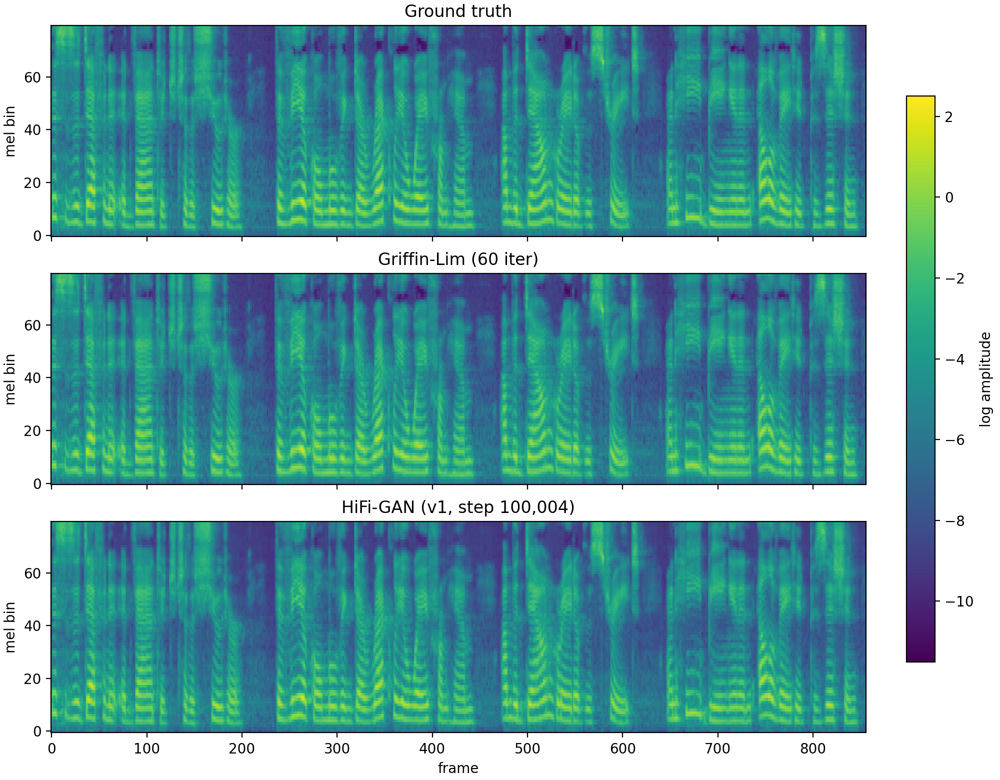

正解


Griffin-Lim


HiFi-GAN


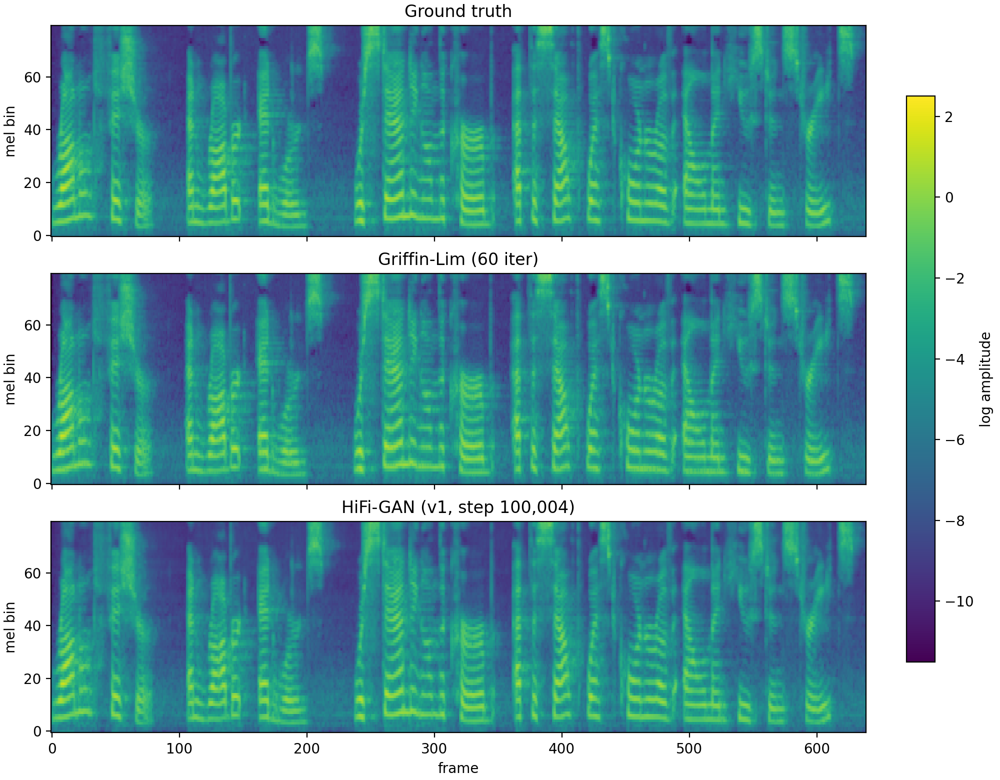

In [ ]:
import librosa
from IPython.display import Audio, Image, display

STEP = None  # 例: 50000（checkpoints/g_0050000.pt を使う）


def load_generator(step=None):
    g = Generator(h).to(device)
    path = f'{CKPT_DIR}/ckpt_latest.pt' if step is None else f'{CKPT_DIR}/g_{step:07d}.pt'
    ckpt = torch.load(path, map_location=device)
    g.load_state_dict(ckpt['generator'])
    g.eval()
    print(f'{os.path.basename(path)} を読み込みました（step {ckpt["step"]:,}）')
    return g, ckpt['step']


def griffin_lim(log_mel, length, n_iter=60):
    # 対数メル → 振幅 → 線形スペクトログラムを推定 → 位相を反復推定
    y = librosa.feature.inverse.mel_to_audio(
        np.exp(log_mel), sr=h.sampling_rate, n_fft=h.n_fft, hop_length=h.hop_size,
        win_length=h.win_size, power=1.0, n_iter=n_iter, fmin=h.fmin, fmax=h.fmax)
    return librosa.util.fix_length(y, size=length)  # 正解と同じ長さにそろえる


@torch.no_grad()
def compare(path, g, step):
    name = os.path.splitext(os.path.basename(path))[0]
    out_dir = f'{SAMPLE_DIR}/comparison'
    os.makedirs(out_dir, exist_ok=True)

    y = load_wav(path)
    y = y[:len(y) // h.hop_size * h.hop_size]
    mel = mel_input(y.unsqueeze(0).to(device))
    y_gl = torch.from_numpy(griffin_lim(mel[0].cpu().numpy(), len(y))).float()
    y_hf = g(mel).squeeze().cpu()

    sf.write(f'{out_dir}/{name}_griffinlim.wav', y_gl.numpy(), h.sampling_rate)
    sf.write(f'{out_dir}/{name}_hifigan_step{step}.wav', y_hf.numpy(), h.sampling_rate)
    plot_mels([mel[0].cpu().numpy(),
               mel_input(y_gl.unsqueeze(0).to(device))[0].cpu().numpy(),
               mel_input(y_hf.unsqueeze(0).to(device))[0].cpu().numpy()],
              ['Ground truth', 'Griffin-Lim (60 iter)', f'HiFi-GAN ({CONFIG_NAME}, step {step:,})'],
              f'{out_dir}/{name}_compare.png')

    for label, wav in [('正解', y), ('Griffin-Lim', y_gl), ('HiFi-GAN', y_hf)]:
        print(label)
        display(Audio(wav.numpy(), rate=h.sampling_rate))
    display(Image(f'{out_dir}/{name}_compare.png'))


g, g_step = load_generator(STEP)
for path in val_files[:2]:
    compare(path, g, g_step)

## 9. 推論速度の計測（本に載せる用）

10秒分の音声を何秒で生成できるかを測ります。リアルタイムの何倍速か（RTF の逆数）も表示します。

In [ ]:
@torch.no_grad()
def benchmark(g, seconds=10, repeat=10):
    frames = int(seconds * h.sampling_rate / h.hop_size)
    mel = torch.randn(1, h.num_mels, frames, device=device)
    for _ in range(3):  # ウォームアップ
        g(mel)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t = time.time()
    for _ in range(repeat):
        g(mel)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = (time.time() - t) / repeat
    print(f'{seconds}秒の音声の生成: {elapsed * 1000:.1f} ms（実時間の {seconds / elapsed:.0f} 倍速, {device}）')


benchmark(g)